 
# Lecture 21 — Control Unit Design

**Lecture:** [Hardwired and Microprogrammed Control](https://youtu.be/qbZQ-YqPi_c?utm_source=chatgpt.com)

**Professor:** Dr. Janibul Bashir  
**Duration:** Approximately 59 minutes

> 📝 **Transcript note:** The complete timestamped transcript was retrieved through vidIQ in Arabic translation. It is used for topic coverage and sequence rather than verbatim English quotations.

## Lecture Overview

| Timestamp | Topics |
|---|---|
| 0:00–4:55 | Control unit and control signals |
| 4:55–12:18 | Hardwired control unit and Boolean logic |
| 12:18–21:00 | Hardwired limitations |
| 21:00–35:00 | Microprogrammed control concepts |
| 35:00–49:45 | Common bus, microinstructions and micro-PC |
| 50:02–57:39 | Vertical vs horizontal microprogramming |
| 57:39–59:00 | Summary and processor design |

---

## 1. Why Do We Need a Control Unit?

Recall our previous circuit:

```asm
add  x5, x6, x7
addi x5, x6, 10
```

Both instructions use the same ALU, but their second operands differ.

For `add`, the ALU needs the value from `x7`.

For `addi`, the ALU needs the immediate `10`.

**Who tells the multiplexer which one to select?**

The **Control Unit**.

The professor defines the Control Unit as the logic responsible for generating control signals that coordinate data movement and operations inside the processor.

> 💡 **Key distinction:**
>
> - **Datapath:** Performs the actual operations.
> - **Control path:** Tells the datapath what to do.

---

## 2. Two Approaches to Designing the Control Unit

### 2.1 Hardwired Control

Dedicated logic gates generate control signals directly from decoded instruction fields.

### 2.2 Microprogrammed Control

Stored microinstructions determine the sequence of control signals.

| Approach | How Control Signals Are Generated |
|---|---|
| Hardwired Control | Dedicated hardware logic gates |
| Microprogrammed Control | Stored microinstructions |

Let's begin with hardwired control.

---

## 3. Hardwired Control — Generating `isLoad`

### 3.1 RISC-V Load Opcode

A standard RISC-V load instruction has the opcode:

```text
0000011
```

The Control Unit needs to detect this bit pattern.

It can do that with a Boolean circuit consisting of **NOT** and **AND** gates.

### 3.2 Boolean Expression

For opcode bits $b_6,\ldots,b_0$:

$$
\boxed{
isLoad =
\overline{b_6}\,
\overline{b_5}\,
\overline{b_4}\,
\overline{b_3}\,
\overline{b_2}\,
b_1b_0
}
$$

When the opcode matches `0000011`, the expression evaluates to **1**.

Otherwise, it evaluates to **0**.

### 3.3 Hardware Circuit



### 3.4 Key Principle
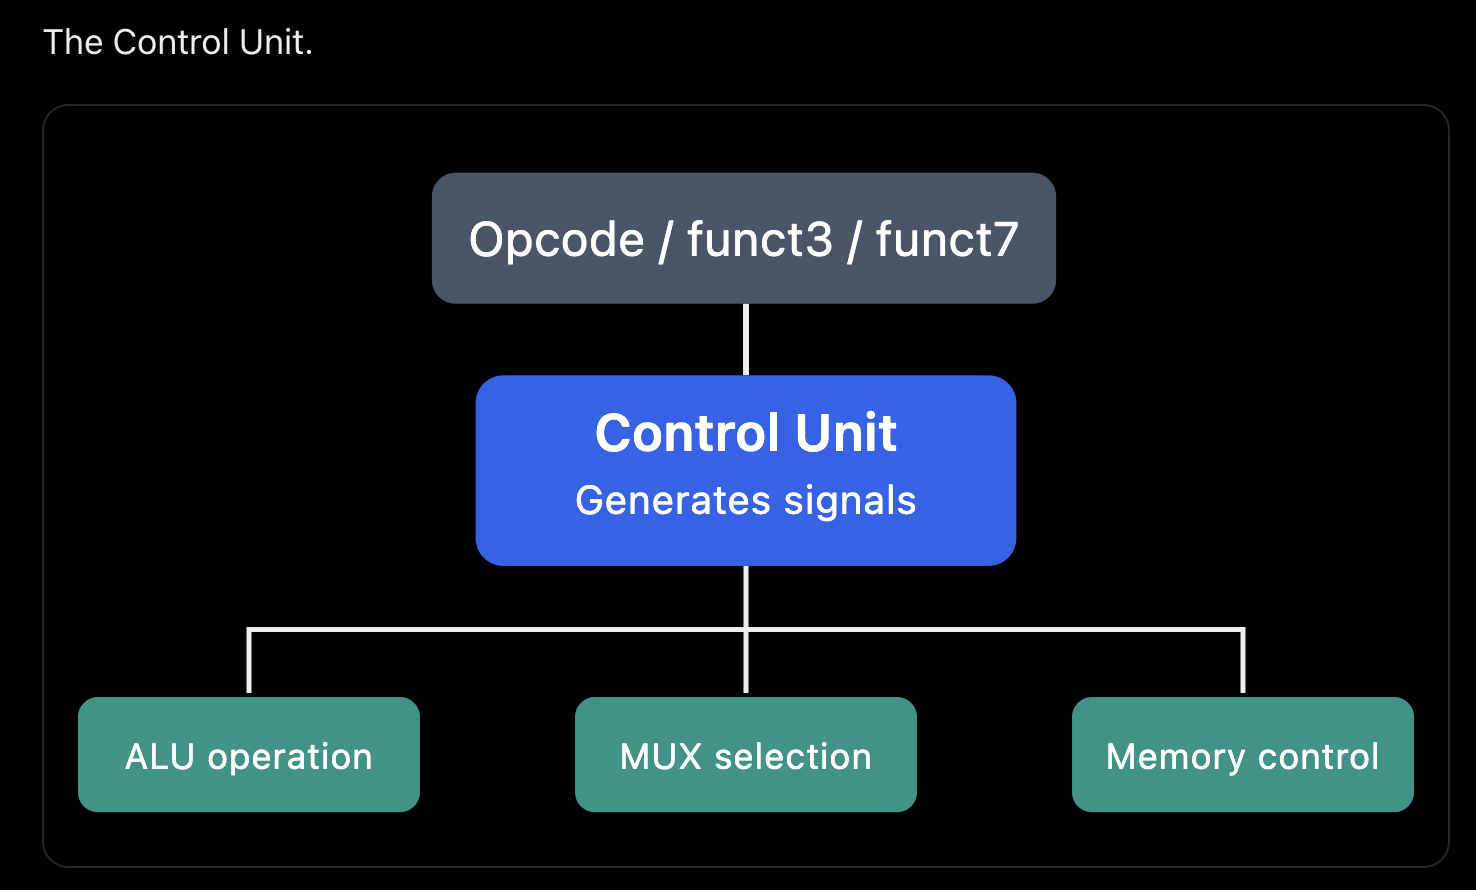
> 💡 **Hardwired Control:** Fixed hardware logic decodes instruction fields into control signals.

---



# Lecture 21 — Part 2: Hardwired Control Unit

---

## 1. How Do Boolean Circuits Generate Control Signals?

We already know the basic idea:

$$
\boxed{\text{Instruction bits} \longrightarrow \text{Logic gates} \longrightarrow \text{Control signals}}
$$

Let's derive the circuit rather than memorize it.

Suppose the opcode contains seven bits:

**RISC-V LOAD opcode = `0000011`**

| Bit | Value |
|---|---|
| $b_6$ | 0 |
| $b_5$ | 0 |
| $b_4$ | 0 |
| $b_3$ | 0 |
| $b_2$ | 0 |
| $b_1$ | 1 |
| $b_0$ | 1 |

For `isLoad` to become `1`, **all seven bits must match**.

We need:

$$
b_6=0,\ b_5=0,\ b_4=0,\ b_3=0,\ b_2=0,\ b_1=1,\ b_0=1
$$

### How Do We Detect That?

- A NOT gate converts an expected `0` bit into a logical `1`.
- A bit expected to be `1` is used directly.
- An AND gate combines all seven conditions.

Therefore:

$$
\boxed{
isLoad =
\overline{b_6}\cdot
\overline{b_5}\cdot
\overline{b_4}\cdot
\overline{b_3}\cdot
\overline{b_2}\cdot
b_1\cdot b_0
}
$$

If the opcode is exactly `0000011`, all the AND conditions evaluate to 1.

Thus:

$$
\boxed{isLoad=1}
$$

For any other opcode, at least one required condition is false, so `isLoad = 0`.

> 💡 **Key principle:** This is how a hardwired control circuit recognizes instructions.

---

## 2. Professor's Second Example — Generating `isCall`

**Transcript: Approximately 9:48–11:42**

Recall Lecture 20, where the professor introduced the control signal `isCall`.

It becomes active for:

```asm
jal  x1, target
jalr x1, 0(x5)
```

**Why?**

Because both instructions write a return address into the destination register.

### 2.1 Instruction Opcodes

| Instruction | Opcode |
|---|---|
| `jal` | `1101111` |
| `jalr` | `1100111` |

The Control Unit must generate:

$$
\boxed{isCall=1}
$$

when either opcode occurs.

### 2.2 Deriving the Boolean Expressions

Let's first define two Boolean expressions:

**For JAL:**

$$
JAL=b_6b_5\overline{b_4}b_3b_2b_1b_0
$$

**For JALR:**

$$
JALR=b_6b_5\overline{b_4}\overline{b_3}b_2b_1b_0
$$

Because either instruction should activate the signal, we combine the expressions using **OR**:

$$
\boxed{isCall=JAL+JALR}
$$

### Boolean Notation

| Symbol | Meaning |
|---|---|
| $\cdot$ or multiplication | Logical AND |
| $+$ or addition | Logical OR |
| $\overline{b}$ | Logical NOT |

### 2.3 Simplifying the Boolean Expression

Notice that `jal` and `jalr` differ only in bit $b_3$.

We can simplify the expression:

$$
isCall=
b_6b_5\overline{b_4}b_2b_1b_0
(b_3+\overline{b_3})
$$

Since:

$$
b_3+\overline{b_3}=1
$$

We get:

$$
\boxed{
isCall=b_6b_5\overline{b_4}b_2b_1b_0
}
$$

> 💡 This is a useful example of **Boolean simplification reducing hardware complexity**.

In a complete decoder, additional instruction-validity checks may also be necessary; this expression detects the two relevant opcode patterns.


---

## 3. What Exactly Makes a Control Unit Hardwired?

Here's the important point.

The circuit is constructed using **fixed logic elements**.

For example:

```text
LOAD opcode
     ↓
NOT and AND gates
     ↓
isLoad = 1
```

Once the processor is manufactured, that circuit's logic is fixed.

Suppose we want to change which control signals are generated for an instruction.

With ordinary hardwired control, we cannot simply edit a stored sequence of microinstructions.

We would need:

- A different hardware implementation, or
- A hardware reconfiguration mechanism.

That brings us to the professor's central example.

---

## 4. Professor's Multiplication Example

**Transcript: Approximately 12:49–19:30**

Suppose we have an instruction:

```asm
mul x5, x6, x7
```

The processor contains a **dedicated multiplier**.

The hardwired Control Unit recognizes `mul` and generates:

```text
isMultiply = 1
```

The multiplier performs the operation.

### What Happens if the Multiplier Is Defective?

Now imagine that the multiplier is defective.

Could we instead perform multiplication through repeated addition?

**Mathematically, yes.**

For example:

$$
4\times3=4+4+4=12
$$

But the fixed hardwired control logic cannot automatically switch to an alternative micro-operation sequence unless that fallback was explicitly designed into the hardware.

> 💡 **Professor's key point:** This illustrates the limited flexibility of hardwired control.

> 📝 **Technical clarification:** `mul` is supported by the RISC-V M extension, even though the professor treats it as a hypothetical operation in his simplified processor.

---

## 5. Advantages and Disadvantages of Hardwired Control

| Advantages | Disadvantages |
|---|---|
| Fast control-signal generation | Difficult to modify after implementation |
| No control memory required | Complex instruction behavior can require complicated logic |
| Efficient for simple instruction sets | Adding instructions usually requires hardware redesign |
| Often lower control-path overhead | Less flexible than stored microcode |

### Exam Definition

> 📌 **Hardwired Control Unit:** A control unit in which control signals are generated using dedicated, fixed combinational and/or sequential logic circuits based on instruction fields and processor state.

---

## 6. Why Do We Need Another Approach?

Now consider what the professor is trying to establish.

In hardwired control:

$$
\text{Instruction}
\rightarrow
\text{Fixed control logic}
\rightarrow
\text{Signals}
$$

**What if**, instead of permanently wiring every sequence of control actions, we stored those actions as a program inside the processor?

Then an instruction could be implemented through a sequence of smaller operations.

That is the idea behind the **Microprogrammed Control Unit**.

### Topics Coming Next

- Control memory
- Microinstructions
- Micro-PC
- Horizontal versus vertical microprogramming

---


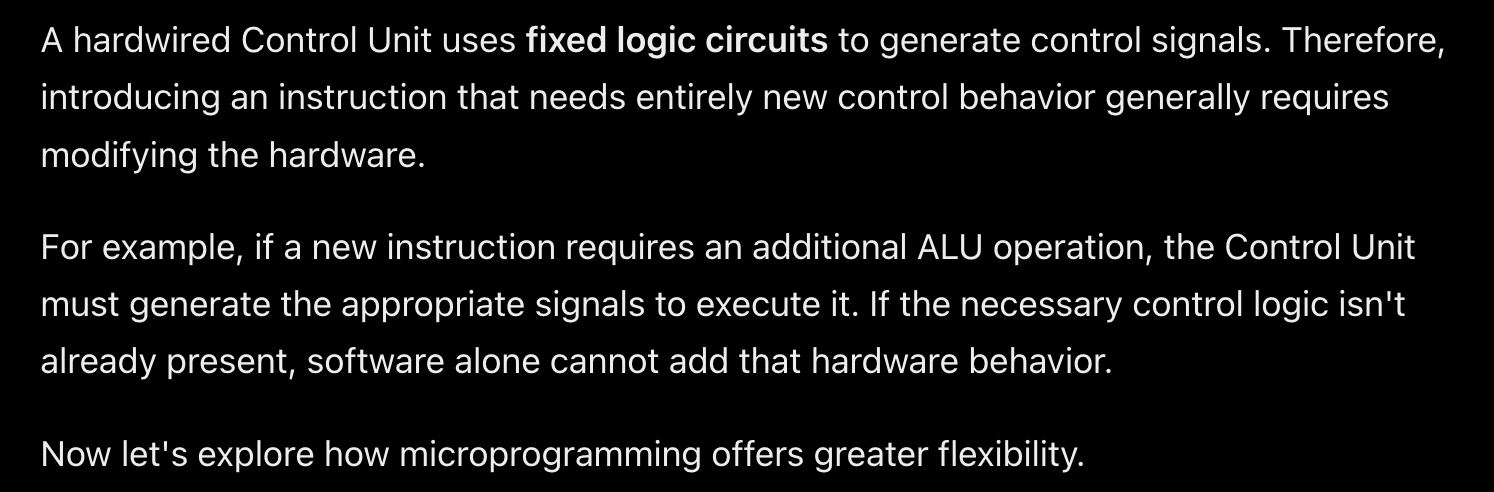


# Lecture 21 — Part 3: Microprogrammed Control Unit

**Professor:** Dr. Janibul Bashir  
**Transcript:** Approximately 21:00–50:00

---

## 1. First, Let's Identify the Problem

In **hardwired control**, an instruction such as:

```asm
add x5, x6, x7
```

is decoded by fixed circuitry that produces the required control signals.

But think about what happens inside the processor.

Even this simple instruction needs several operations:

1. Fetch the instruction from memory.
2. Decode it.
3. Read registers `x6` and `x7`.
4. Perform addition using the ALU.
5. Store the result in `x5`.

Each operation requires specific control signals.

**What if we could store the sequence of these control actions in memory instead of constructing fixed logic for every sequence?**

That's the central idea of **microprogramming**.

---

## 2. What Is a Microprogrammed Control Unit?

> **Definition:** A microprogrammed Control Unit generates control signals by fetching and executing microinstructions stored in a special memory called **control memory**.

### 2.1 Three Important Concepts

| Term | Meaning |
|---|---|
| Machine instruction | Instruction visible to the programmer, such as `add` |
| Microinstruction | Internal control instruction specifying one set of hardware actions |
| Microprogram | Sequence of microinstructions implementing a machine instruction |

### 2.2 Example: Implementing an `add` Instruction

Consider the machine instruction:

```asm
add x5, x6, x7
```

It could be implemented internally using these illustrative microinstructions:

```text
MI1: Read register x6 into A
MI2: Read register x7 into B
MI3: Perform A + B using ALU
MI4: Write ALU result into x5
```

> 💡 **Important:** These are not four RISC-V instructions. They are internal control operations used to implement **one RISC-V instruction**.

They could be combined differently depending on the processor design.

---

## 3. Architecture of the Microprogrammed Control Unit
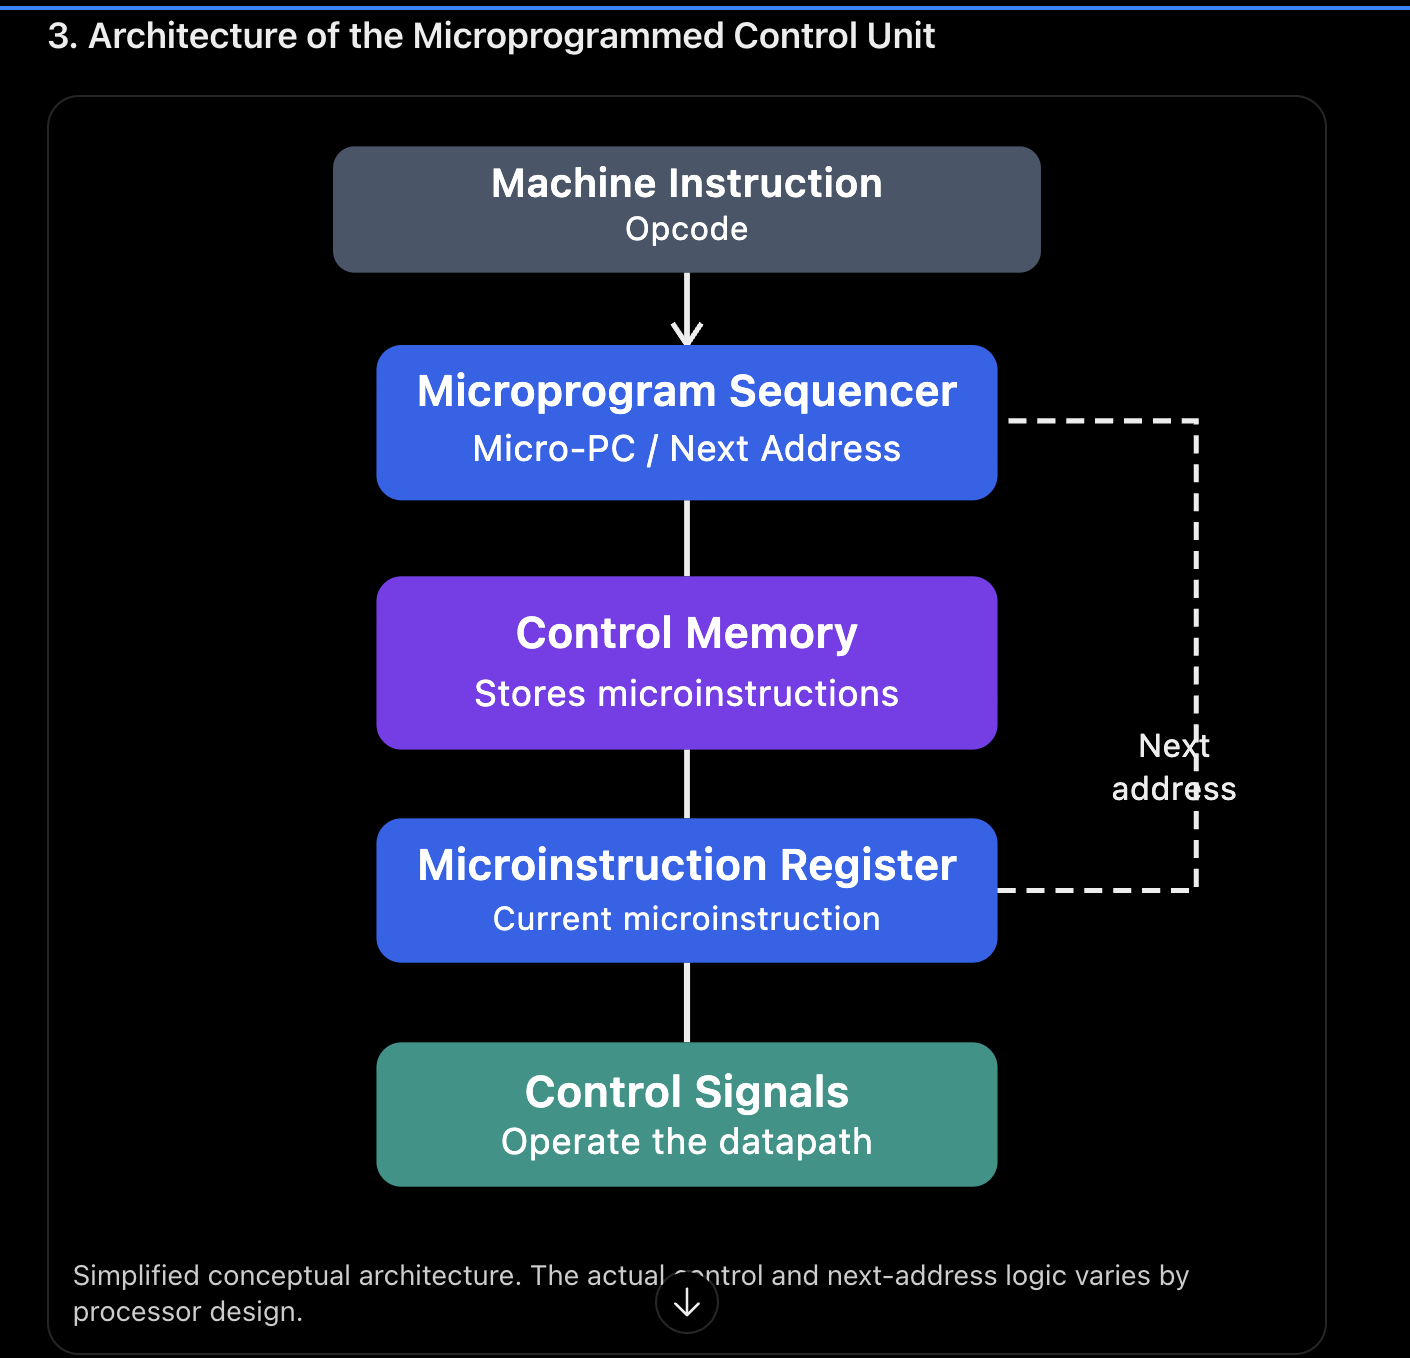


*Simplified conceptual architecture. The actual control and next-address logic varies by processor design.*

### 3.1 Control Memory

Stores the microprograms.

Each location contains a **microinstruction** or **control word**.

### 3.2 Microprogram Counter (micro-PC)

Holds the address of the **next microinstruction** to execute.

This is different from the normal PC, which addresses machine instructions.

### 3.3 Microprogram Sequencer

Determines the next microinstruction address, including:

- Sequential execution
- Conditional microbranches

### 3.4 Microinstruction Register

Holds the current microinstruction.

Its fields are decoded or used directly to activate control signals.

---

## 4. How Does the Microprogram Execute?

Let's use a hypothetical instruction:

```asm
add x5, x6, x7
```

Suppose the microprogram for `add` starts at control-memory address `100`.

### 4.1 Control Memory Contents — Illustrative Example

| Address | Microinstruction |
|---|---|
| 100 | Read x6 into A |
| 101 | Read x7 into B |
| 102 | ALU: A + B → result |
| 103 | Write result into x5 |

### 4.2 Microinstruction Execution


**Step 1 of 4 — Micro-PC = 100**

**Read first operand**

The micro-PC points to address `100`.

The control unit fetches `MI1` and activates signals to read `x6` into temporary register `A`.

### 4.3 Remaining Microinstruction Sequence

**Step 2 of 4 — Micro-PC = 101**

```text
MI2: Read x7 into B
```

**Step 3 of 4 — Micro-PC = 102**

```text
MI3: ALU performs A + B → result
```

**Step 4 of 4 — Micro-PC = 103**

```text
MI4: Write result into x5
```

### 4.4 Difference from Hardwired Control

Now notice the difference from hardwired control.

**In hardwired control:**

A fixed logic network produces the control signals.

**In microprogrammed control:**

The microinstructions specify those control signals in sequence.

> 💡 This makes complex instruction behavior easier to organize.

---

## 5. The Professor's Common-Bus Datapath Example

**Transcript:** Approximately 35:00–46:58

Around this point, the professor describes a datapath in which several hardware units communicate using a **common bus**.

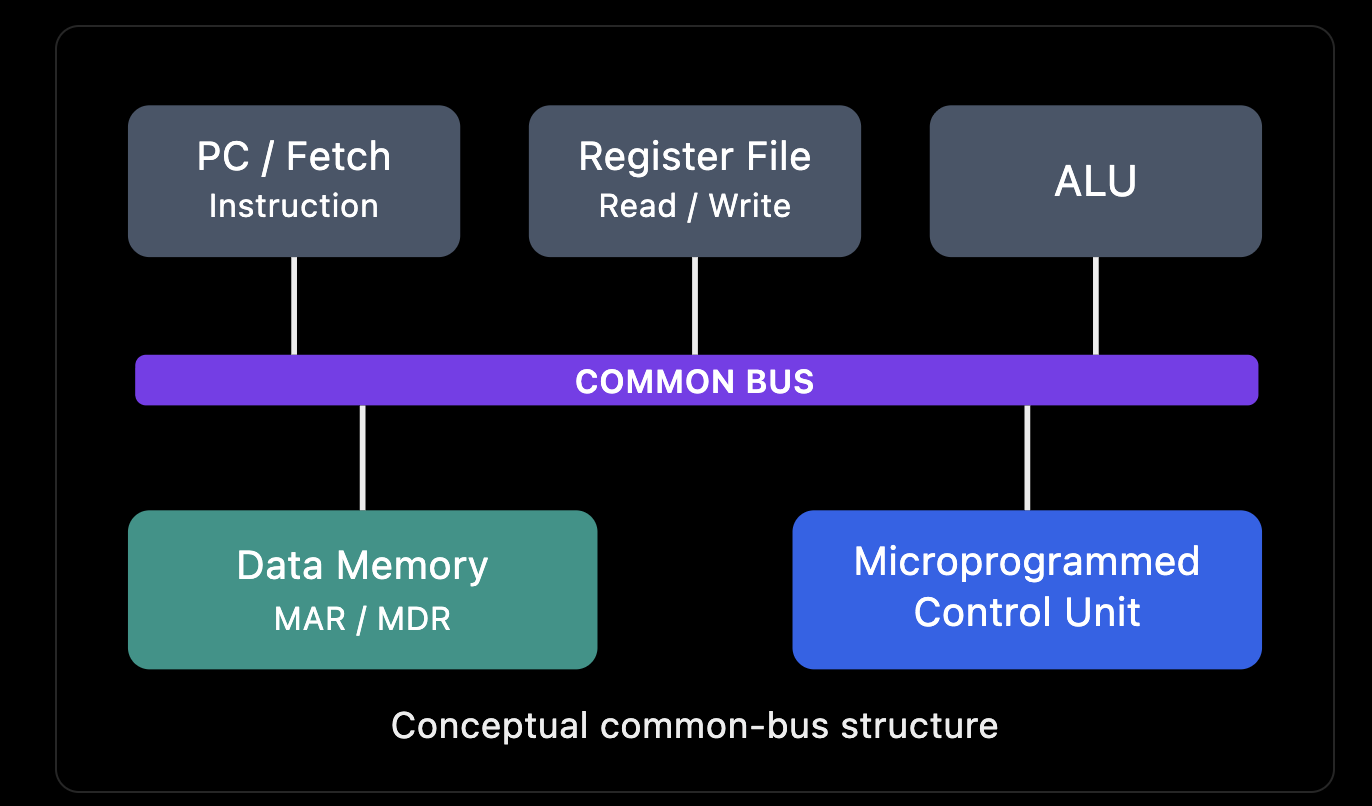

### 5.1 Components and Responsibilities

| Component | Responsibility |
|---|---|
| Register File | Supplies operands |
| ALU | Processes data held in temporary registers such as A and B |
| Memory Unit | Performs reads and writes using MAR and MDR |
| Microprogrammed Control Unit | Determines which transfers and operations occur at each step |

### 5.2 How Does the Common Bus Work?

A common bus allows multiple units to share data-transfer connections.

However, generally **only one source may drive a conventional shared bus at a time**.

The control sequence coordinates these transfers.

### 5.3 Why Does the Professor Introduce This Architecture?

The reason the professor introduces this architecture is to show how **microinstructions can coordinate complex datapath operations one step at a time**.

---

## 6. Hardwired vs Microprogrammed Control

| Feature | Hardwired | Microprogrammed |
|---|---|---|
| Signal generation | Logic circuits | Stored microinstructions |
| Speed | Generally faster | Often slower due to microinstruction sequencing |
| Flexibility | Lower | Higher |
| Implementation | Control logic network | Control memory and sequencer |
| Complex operations | Can increase logic complexity | Often easier to express as sequences |
| Modifications | Typically hardware redesign | Microcode changes where supported |

### Important Qualification

> 📌 Not every microprogrammed processor supports field updates to its microcode, and microprogramming cannot create hardware capabilities that do not exist.

---



# Lecture 21 — Part 4: Vertical vs Horizontal Microprogramming

**Professor's Transcript:** 50:02–57:39

---

## 1. Why Do We Need Different Microinstruction Formats?

We already know that a **microinstruction** controls hardware operations inside the processor.

For example, suppose our processor has four possible control signals:

| Control Signal | Function |
|---|---|
| `RegRead` | Read a register |
| `ALUAdd` | Perform addition |
| `MemRead` | Read memory |
| `RegWrite` | Write to a register |

The question is:

**How should we represent these control signals inside a microinstruction?**

There are two main approaches:

1. **Vertical microprogramming** — encoded control signals.
2. **Horizontal microprogramming** — control signals represented more directly.

Let's derive both.

---

## 2. Vertical Microprogramming

Suppose we have four possible operations:

| Operation | Binary Code |
|---|---|
| Register read | `00` |
| ALU addition | `01` |
| Memory read | `10` |
| Register write | `11` |

Instead of storing a separate bit for every signal, we can store just a **2-bit operation code**.

For example:

```text
01
```

This means **ALU addition**.

But there's a problem.

The processor cannot directly interpret `01` as four independent control signals.

**We need a decoder.**

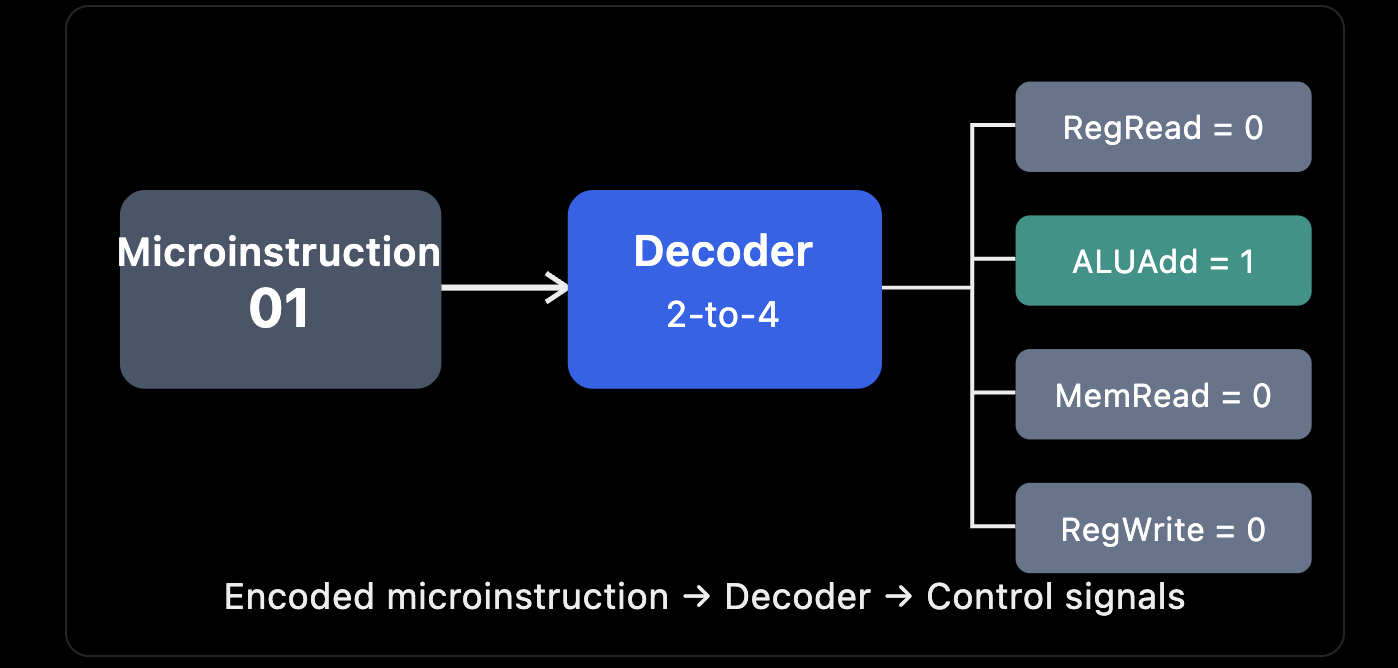

### 2.1 Definition

> **Vertical Microprogramming:** A microinstruction encoding technique in which control operations are represented using compact binary codes that must be decoded to generate the required control signals.

### 2.2 Advantages

- Smaller microinstruction width.
- Less control-memory storage required.
- Compact representation of control operations.

### 2.3 Disadvantages

- Additional decoding circuitry is needed.
- Decoding can increase control-signal generation delay.
- Encoding can restrict which operations are activated simultaneously.

> 💡 The professor's central point is that vertical microinstructions resemble ordinary machine instructions because they use encoded operation fields.

---

## 3. Horizontal Microprogramming

Now imagine that instead of encoding the operation, we store **a bit for each control signal**.

Using the same four signals:
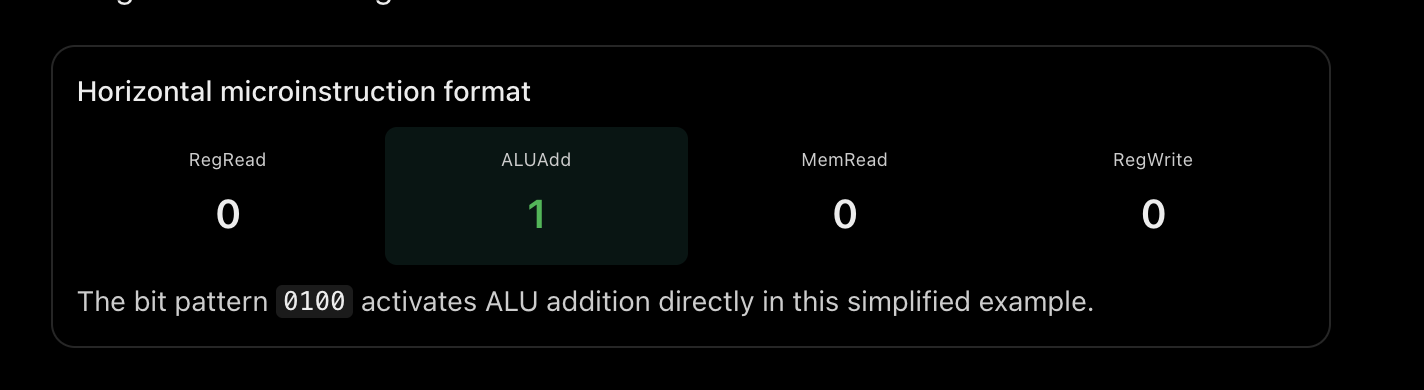

### 3.1 Horizontal Microinstruction Format

| `RegRead` | `ALUAdd` | `MemRead` | `RegWrite` |
|---|---|---|---|
| 0 | 1 | 0 | 0 |

The bit pattern `0100` activates **ALU addition** directly in this simplified example.

Notice the difference.

In vertical microprogramming, `01` is an encoded operation that must be decoded.

In horizontal microprogramming, each bit represents a control signal directly.

Therefore, we don't need the same operation-decoding stage to identify which of these four signals should be activated.
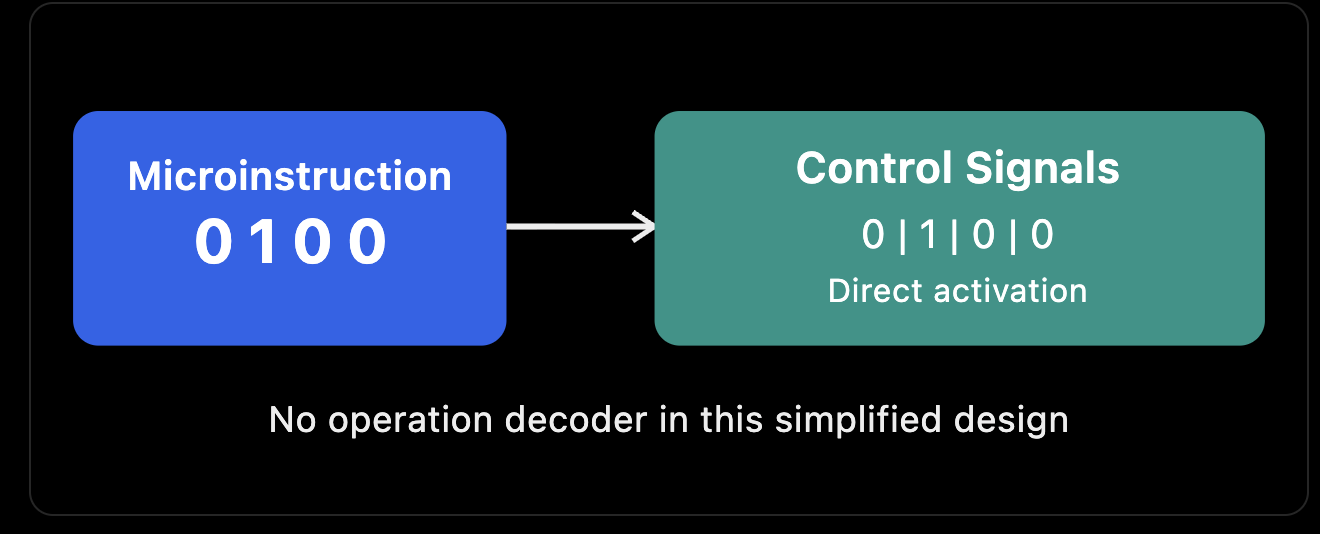

### 3.2 Definition

> **Horizontal Microprogramming:** A microinstruction encoding technique in which individual bits or fields directly specify control signals, allowing multiple compatible micro-operations to be activated simultaneously.

### 3.3 Advantages

- Faster control-signal generation due to less decoding.
- Greater potential for parallel micro-operations.
- Simpler direct control of datapath components.

### 3.4 Disadvantages

- Wider microinstructions.
- Greater control-memory requirements.
- More unused or redundant bit combinations may exist.

> 📌 **Important distinction:** Horizontal encoding doesn't mean every control signal can be activated simultaneously. Some combinations are electrically or logically incompatible.

---

## 4. Why Does Horizontal Microprogramming Require More Storage?

Let's understand this mathematically.

Suppose there are **16 independent control signals**.

### 4.1 Horizontal Encoding

In a fully unencoded horizontal scheme, we need:

$$
\boxed{16\text{ bits per microinstruction}}
$$

Each bit represents one control signal.

### 4.2 Vertical Encoding

If only one of those 16 operations can be selected at a time, a fully encoded vertical scheme could represent the selection using:

$$
n=\lceil\log_2 16\rceil
$$

$$
\boxed{n=4\text{ bits}}
$$

### 4.3 Comparison

| Format | Bits per Microinstruction |
|---|---|
| Vertical | **4 bits** |
| Horizontal | **16 bits** |

However, the compact **4-bit encoding** can select only one of the 16 operations at a time.

A **16-bit horizontal control word** can represent many combinations, subject to hardware constraints.

That's the trade-off:

$$
\boxed{\text{Compact encoding}\longleftrightarrow\text{Direct, flexible control}}
$$

> 📌 **Important:** In actual processors, microinstructions often contain multiple fields, including sequencing information. Therefore, these bit widths are illustrative rather than universal.

---

## 5. Vertical vs Horizontal — Exam Comparison

| Feature | Vertical | Horizontal |
|---|---|---|
| Encoding | Highly encoded | Less encoded or unencoded |
| Instruction width | Narrower | Wider |
| Decoder | Usually required | Less decoding |
| Control memory | Lower requirement | Higher requirement |
| Speed | Generally slower | Generally faster |
| Parallelism | More restricted | Greater potential |
| Control signal generation | Indirect | More direct |

### Most Important Exam Distinction

> 💡 **Vertical microprogramming** saves control-memory space through encoding, whereas **horizontal microprogramming** sacrifices storage efficiency for more direct control and greater potential parallelism.

---

## 6. Lecture 21 — Final Conceptual Summary

We have now covered the professor's main concepts in **Lecture 21**.

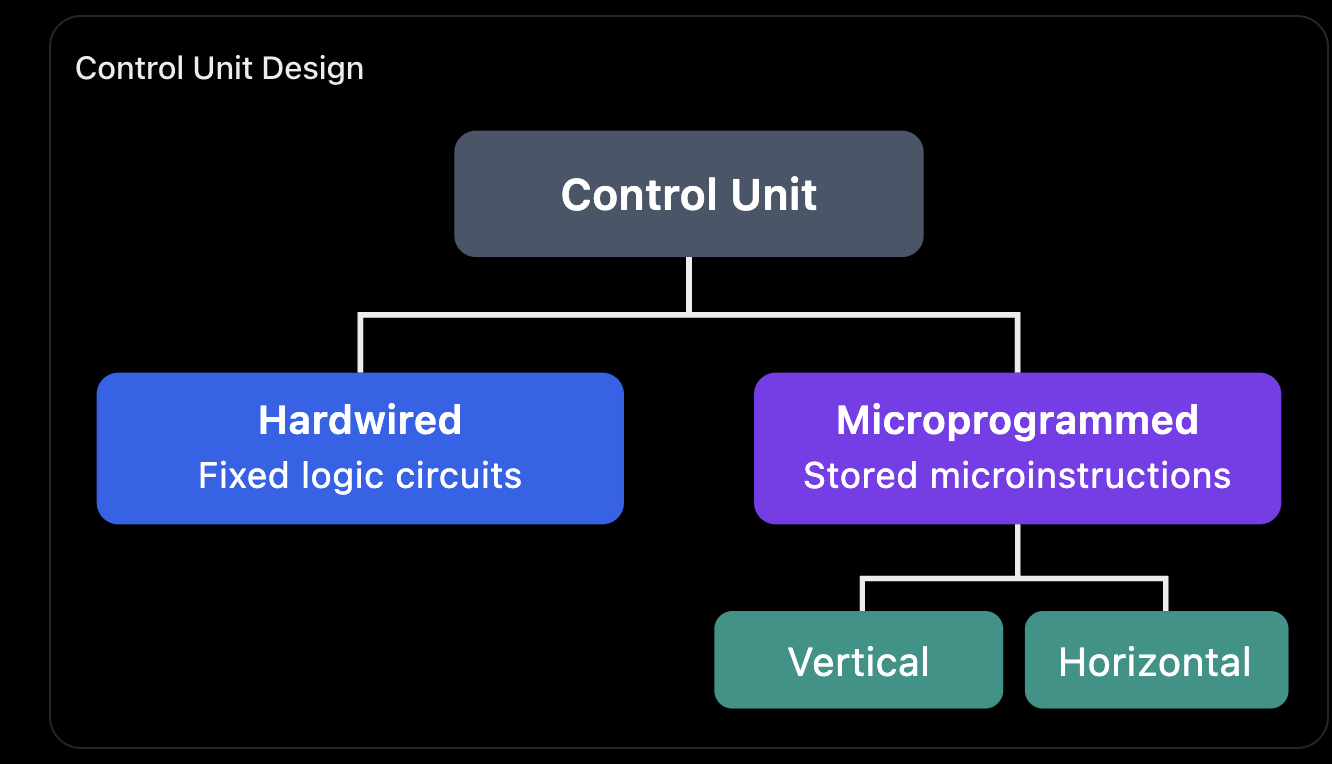

### Control Unit Design

The professor closes by noting that practical processors may combine **hardwired control** for efficient common operations with **microcoded mechanisms** for more complex behavior.

> 📌 This is an architectural choice, not a requirement for every processor.

---


# Lecture 21 — Quick Exam Revision

---

## 1. Control Unit

**Definition:** The **Control Unit** is the component of the processor responsible for generating control signals that coordinate the operation of the datapath.

---

## 2. Hardwired vs Microprogrammed Control

| Feature | Hardwired Control | Microprogrammed Control |
|---------|-------------------|-------------------------|
| Implementation | Fixed logic circuits | Control memory + microprogram sequencer |
| Signal generation | Boolean logic | Microinstructions |
| Speed | Generally faster | Generally slower |
| Flexibility | Difficult to modify | More flexible |
| Control memory | Not required | Required |
| Complex instructions | More complex logic | Easier to organize as microprograms |

For **hardwired** control, remember:

$$\text{Opcode, funct3, funct7} \rightarrow \text{Logic Gates} \rightarrow \text{Control Signals}$$

For **microprogrammed** control:

$$\text{Opcode} \rightarrow \text{Microprogram} \rightarrow \text{Microinstructions} \rightarrow \text{Control Signals}$$

---

## 3. Important terms

| Term | Meaning |
|------|---------|
| **Microinstruction** | Internal instruction specifying control actions |
| **Microprogram** | Sequence of microinstructions implementing a machine instruction |
| **Control Memory** | Stores microprograms |
| **Micro-PC** | Holds the address of the next microinstruction |
| **Microprogram Sequencer** | Determines which microinstruction executes next |

---

## 4. Vertical vs Horizontal Microprogramming

| Feature | Vertical | Horizontal |
|---------|----------|------------|
| Encoding | Highly encoded | Less encoded |
| Instruction width | Narrow | Wide |
| Decoding | More | Less |
| Speed | Generally slower | Generally faster |
| Parallel operations | More restricted | Greater potential |
| Memory requirement | Lower | Higher |

---

## 5. Three likely theory questions

1. Explain hardwired and microprogrammed Control Units with diagrams.
2. Compare hardwired and microprogrammed control.
3. Differentiate vertical and horizontal microprogramming.

> 📌 You should now be able to answer these without memorizing the professor's hour-long explanation.